# Q-Learning for a Gridworld Maze

The objective is to train an autonomous reinforcement learning agent to find the optimal, shortest obstacle-free path from a fixed starting position to a target goal inside a maze. The agent begins with zero prior knowledge of the maze layout and learns purely through trial, error, and delayed rewards using the model-free, off-policy Q-learning algorithm.

---

### The Maze Environment and MDP Setup

The problem is modeled as a discrete Markov Decision Process (MDP):

1. **State Space and Layout**:
   - The environment is an **8×8 grid** comprising 64 discrete coordinate states labeled `(row, col)`.
   - **Start Position**: Top-left corner at `(0, 0)`.
   - **Goal Position**: Near the middle-right boundary at `(5, 7)`.
   - **Obstacles**: Interior walls are placed throughout the maze to block direct horizontal or vertical travel, forcing the agent to navigate through winding corridors.

2. **Action Space**:
   - At each time step, the agent can choose from 4 cardinal actions: **UP** (decrease row), **DOWN** (increase row), **LEFT** (decrease column), or **RIGHT** (increase column).
   - If the agent attempts to move into a wall or step beyond the 8×8 grid boundary, it is bounced back into its current position and receives a penalty.

3. **Reward Signal Design**:
   - **Reaching the Goal**: Rewards **+100.0** points and terminates the episode immediately.
   - **Living Step Penalty**: Costs **-1.0** point for every valid step taken. This penalty creates urgency, penalizing unnecessary wandering and driving the agent to discover the shortest possible route.
   - **Wall Collision Penalty**: Costs **-5.0** points whenever the agent runs into a boundary or wall obstacle, teaching it to steer clear of walls.

---

### Hyperparameters and Exploration Strategy

The agent’s learning behavior is governed by several core hyperparameters:

- **Learning Rate ($\alpha = 0.1$)**: Controls how rapidly new information overwrites old estimates in the Q-table.
- **Discount Factor ($\gamma = 0.95$)**: Determines the present value of future delayed rewards, motivating the agent to look ahead toward the final +100 goal reward.
- **Epsilon-Greedy Strategy ($\epsilon$-Greedy)**:
  - Balances exploration (discovering new routes) with exploitation (following the best known path).
  - Starts at an exploration rate of **1.0** (100% random movements at the beginning).
  - Decays exponentially by a multiplier of **0.995** after each episode until it hits a floor of **0.01** (99% exploitation, 1% exploration).
- **Training Horizon**: 2,000 total episodes.
- **Step Cap per Episode**: Capped at 200 steps to prevent the agent from wandering endlessly in early training before finding the goal.

---

### The Q-Learning Mechanism

- **The Q-Table**:
  A 3-dimensional NumPy lookup table with dimensions $8 \times 8 \times 4$ (storing an estimated expected future return for every state-action pair), initialized completely to zeros.
- **Action Selection**:
  With probability $\epsilon$, the agent picks an action completely at random. Otherwise, it selects the action that maximizes the current Q-value for that state, breaking ties randomly to avoid directional bias.
- **Temporal Difference (TD) Update Rule**:
  After executing an action and observing the immediate reward and next state, the Q-table updates using the Bellman equation:
  The updated Q-value equals the old Q-value plus $\alpha$ multiplied by the Temporal Difference error (the immediate reward plus $\gamma$ times the maximum possible Q-value in the next state, minus the old Q-value). When the agent enters the terminal goal cell, the future expected value is set to zero.

---

### Training Progression and Results

The notebook logs training metrics across all 2,000 episodes:

- **Early Exploration Phase (Episodes 1 to 200)**:
  In the beginning, the agent acts almost entirely randomly. During the first 100 episodes, it frequently bumps into walls and wanders near the step limit. The average reward during the first 100 episodes is **-148.5**, and the average episode duration is **90.7 steps**. By Episode 200, $\epsilon$ drops to 0.367, the average reward improves to -49.3, and steps decrease to 59.5.
- **Transition and Rapid Improvement (Episodes 200 to 600)**:
  As the goal reward propagates backward, the agent starts exploiting successful pathways. By Episode 400, average reward turns positive to **+74.3**, and average steps drop sharply to **19.1**. By Episode 600, reward reaches **+83.4** and steps drop to **15.4**.
- **Convergence and Stabilization (Episodes 800 to 2000)**:
  By Episode 1,000, $\epsilon$ reaches its minimum threshold of 0.01. The policy becomes rock solid. Across episodes 1,000 to 2,000, the average reward stabilizes at **+86.6 to +86.7**, and average episode length stabilizes at **14.1 steps**.
- **Final Numerical Comparison**:
  - Over the **first 100 episodes**: Average reward was **-148.5** and average steps were **90.7**.
  - Over the **last 100 episodes**: Average reward improved to **+86.7** and average steps dropped to **14.1**.

---

### Optimal Path Found by the Learned Policy

When the final trained Q-table is evaluated deterministically (pure greedy policy, $\epsilon = 0$):

1. **Success**: The agent reaches the goal without error (`Greedy path reached goal: True`).
2. **Path Length**: It completes the maze in exactly **14 steps** (the absolute theoretical minimum possible distance through the maze).
3. **Exact Coordinates Followed**:
   - Starts at `(0, 0)`
   - Moves straight down along the left column: `(1, 0) -> (2, 0) -> (3, 0) -> (4, 0)`
   - Turns right through the central opening: `(4, 1) -> (4, 2) -> (4, 3) -> (4, 4) -> (4, 5)`
   - Steps down through the southern corridor: `(5, 5) -> (6, 5)`
   - Walks along the bottom opening: `(6, 6) -> (6, 7)`
   - Moves up into the goal cell: `(5, 7)`

---

### Generated Plots and Artifacts

The notebook saved 5 visual figures illustrating the learning process:

1. **`fig1_maze.png`**: A clean grid visualization of the $8 \times 8$ environment showing wall obstacles in black, Start marked with a green "S", and Goal marked with a red "G".
2. **`fig2_reward_curve.png`**: The learning curve showing raw episode returns and a 50-episode moving average climbing out of negative penalty territory and leveling off around +87.
3. **`fig3_steps_curve.png`**: The step-count curve showing how the number of moves per episode plummeted from 100+ steps down to a flat line of 14 steps.
4. **`fig4_policy_path.png`**: A vector-field plot showing the entire maze where each open cell displays an arrow ($\uparrow, \downarrow, \leftarrow, \rightarrow$) pointing in the direction of the highest Q-value, overlaid with an orange trace of the optimal 14-step route.
5. **`fig5_value_heatmap.png`**: A state-value heatmap plotting $V(s) = \max_a Q(s, a)$. It visually depicts value diffusion across the maze: cells adjacent to the goal glow in bright yellow/green (high expected value), while cells further away or near dead-ends are dark purple (lower value).

## 1. Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Fixed seed -> same results every run (important for the report)
rng = np.random.default_rng(42)

## 2. Maze definition, MDP components and hyperparameters

In [2]:
# S = start, G = goal, # = wall, . = free cell
MAZE = [
    "S.#.....",
    ".##.###.",
    "....#...",
    ".####.#.",
    "......#.",
    ".####.#G",
    "....#...",
    "###...#.",
]

# Action space: index 0..3 maps to a (row, col) change
ACTIONS = ["UP", "DOWN", "LEFT", "RIGHT"]
DELTAS  = [(-1, 0), (1, 0), (0, -1), (0, 1)]
ARROWS  = ["↑", "↓", "←", "→"]   # used only for drawing the policy

# ---- Hyperparameters ----
ALPHA = 0.1                      # learning rate: how far to move toward the new estimate
GAMMA = 0.95                     # discount factor: how much future reward matters
EPS_START, EPS_END = 1.0, 0.01   # epsilon-greedy: start fully random, end mostly greedy
EPS_DECAY = 0.995                # epsilon is multiplied by this after every episode
EPISODES  = 2000                 # number of training episodes
MAX_STEPS = 200                  # step cap per episode (prevents endless wandering)

# ---- Reward design ----
R_GOAL = 100.0   # reaching the goal
R_STEP = -1.0    # cost of every move -> makes shorter paths score higher
R_WALL = -5.0    # bumping into a wall / boundary

In [3]:
class MazeEnv:
    """Deterministic gridworld. State = (row, col)."""

    def __init__(self, layout):
        self.grid = np.array([list(row) for row in layout])
        self.n_rows, self.n_cols = self.grid.shape
        # Locate start and goal cells in the grid
        self.start = tuple(int(v) for v in np.argwhere(self.grid == "S")[0])
        self.goal  = tuple(int(v) for v in np.argwhere(self.grid == "G")[0])
        self.pos = self.start

    def reset(self):
        """Put the agent back at the start cell and return the state."""
        self.pos = self.start
        return self.pos

    def step(self, action):
        """Apply an action. Returns (next_state, reward, done)."""
        dr, dc = DELTAS[action]
        r, c = self.pos[0] + dr, self.pos[1] + dc

        # Out of bounds or wall -> agent stays where it is, and is penalised
        if not (0 <= r < self.n_rows and 0 <= c < self.n_cols) or self.grid[r, c] == "#":
            return self.pos, R_WALL, False

        # Valid move
        self.pos = (r, c)
        if self.pos == self.goal:
            return self.pos, R_GOAL, True    # terminal state: episode ends
        return self.pos, R_STEP, False


env = MazeEnv(MAZE)
print("Start:", env.start, "| Goal:", env.goal, "| Grid size:", env.grid.shape)

Start: (0, 0) | Goal: (5, 7) | Grid size: (8, 8)


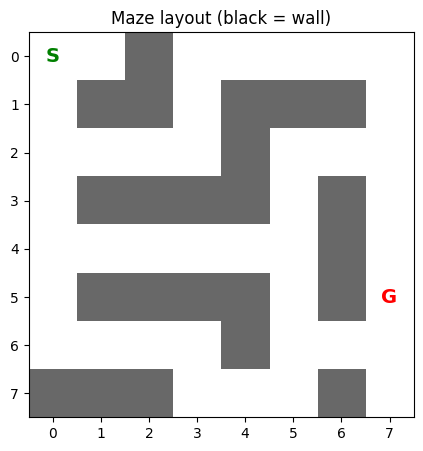

In [4]:
# Visualise the raw maze before any learning (use this figure in the report)
def draw_maze(env, ax):
    img = np.zeros((env.n_rows, env.n_cols))
    img[env.grid == "#"] = 1
    ax.imshow(img, cmap="Greys", vmin=0, vmax=1.5)
    ax.text(env.start[1], env.start[0], "S", ha="center", va="center",
            color="green", fontsize=14, fontweight="bold")
    ax.text(env.goal[1], env.goal[0], "G", ha="center", va="center",
            color="red", fontsize=14, fontweight="bold")
    ax.set_xticks(range(env.n_cols)); ax.set_yticks(range(env.n_rows))

fig, ax = plt.subplots(figsize=(5, 5))
draw_maze(env, ax)
ax.set_title("Maze layout (black = wall)")
plt.savefig("fig1_maze.png", dpi=150, bbox_inches="tight")
plt.show()

## 3. Agent functions: ε-greedy action selection, greedy path, helpers

In [5]:
def choose_action(Q, state, epsilon):
    """Epsilon-greedy: explore with prob. epsilon, otherwise exploit the best known action."""
    if rng.random() < epsilon:
        return int(rng.integers(len(ACTIONS)))        # explore: random action
    q = Q[state]
    # Exploit: argmax, but break ties randomly so early moves aren't biased toward "UP"
    return int(rng.choice(np.flatnonzero(q == q.max())))


def greedy_path(env, Q):
    """Follow the learned greedy policy from start to goal and return the path."""
    state = env.reset()
    path = [state]
    for _ in range(env.n_rows * env.n_cols):          # cap prevents infinite loops if policy is bad
        action = int(np.argmax(Q[state]))
        state, _, done = env.step(action)
        path.append(state)
        if done:
            return path, True
    return path, False


def moving_avg(x, w=50):
    """Smooth a noisy curve with a moving average of window w."""
    return np.convolve(x, np.ones(w) / w, mode="valid")

## 4. Training loop

In [6]:
def train(env):
    # Q-table: one value per (row, col, action); starts at zero
    Q = np.zeros((env.n_rows, env.n_cols, len(ACTIONS)))
    epsilon = EPS_START
    rewards, steps_per_ep = [], []        # logged for the learning curves

    for ep in range(EPISODES):
        state = env.reset()
        total, steps, done = 0.0, 0, False

        while not done and steps < MAX_STEPS:
            # 1) choose an action (epsilon-greedy)
            action = choose_action(Q, state, epsilon)
            # 2) act in the environment, observe reward and next state
            next_state, reward, done = env.step(action)

            # 3) Q-learning update (off-policy TD):
            #    Q(s,a) <- Q(s,a) + alpha * [ r + gamma * max_a' Q(s',a') - Q(s,a) ]
            best_next = 0.0 if done else np.max(Q[next_state])   # no future value at the goal
            td_target = reward + GAMMA * best_next
            Q[state][action] += ALPHA * (td_target - Q[state][action])

            state = next_state
            total += reward
            steps += 1

        # Decay epsilon once per episode (floor at EPS_END)
        epsilon = max(EPS_END, epsilon * EPS_DECAY)
        rewards.append(total)
        steps_per_ep.append(steps)

        # Progress report every 200 episodes
        if (ep + 1) % 200 == 0:
            print(f"Episode {ep + 1:5d} | avg reward (last 200): "
                  f"{np.mean(rewards[-200:]):7.1f} | avg steps: "
                  f"{np.mean(steps_per_ep[-200:]):6.1f} | epsilon: {epsilon:.3f}")

    return Q, rewards, steps_per_ep


Q, rewards, steps_per_ep = train(env)

Episode   200 | avg reward (last 200):   -49.3 | avg steps:   59.5 | epsilon: 0.367
Episode   400 | avg reward (last 200):    74.3 | avg steps:   19.1 | epsilon: 0.135
Episode   600 | avg reward (last 200):    83.4 | avg steps:   15.4 | epsilon: 0.049
Episode   800 | avg reward (last 200):    85.7 | avg steps:   14.5 | epsilon: 0.018
Episode  1000 | avg reward (last 200):    86.7 | avg steps:   14.1 | epsilon: 0.010
Episode  1200 | avg reward (last 200):    86.6 | avg steps:   14.2 | epsilon: 0.010
Episode  1400 | avg reward (last 200):    86.6 | avg steps:   14.2 | epsilon: 0.010
Episode  1600 | avg reward (last 200):    86.6 | avg steps:   14.1 | epsilon: 0.010
Episode  1800 | avg reward (last 200):    86.6 | avg steps:   14.1 | epsilon: 0.010
Episode  2000 | avg reward (last 200):    86.7 | avg steps:   14.1 | epsilon: 0.010


## 5. Results

In [7]:
# Read off the learned path by following argmax Q from the start
path, reached = greedy_path(env, Q)
print("Greedy path reached goal:", reached)
print("Path length (steps):", len(path) - 1)
print("Path:", path)

Greedy path reached goal: True
Path length (steps): 14
Path: [(0, 0), (1, 0), (2, 0), (3, 0), (4, 0), (4, 1), (4, 2), (4, 3), (4, 4), (4, 5), (5, 5), (6, 5), (6, 6), (6, 7), (5, 7)]


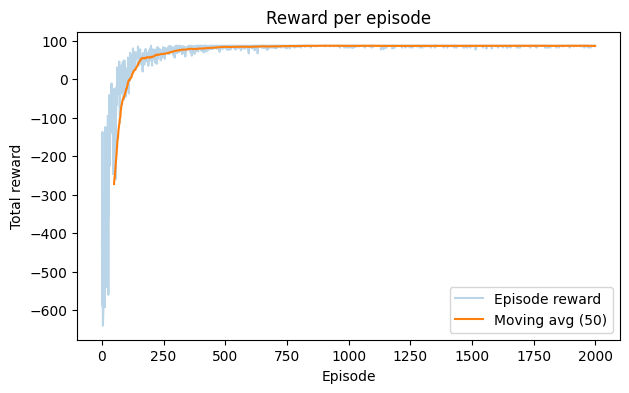

In [8]:
# Figure 2: reward per episode (learning curve)
plt.figure(figsize=(7, 4))
plt.plot(rewards, alpha=0.3, label="Episode reward")
plt.plot(range(49, len(rewards)), moving_avg(rewards), label="Moving avg (50)")
plt.title("Reward per episode"); plt.xlabel("Episode"); plt.ylabel("Total reward")
plt.legend()
plt.savefig("fig2_reward_curve.png", dpi=150, bbox_inches="tight")
plt.show()

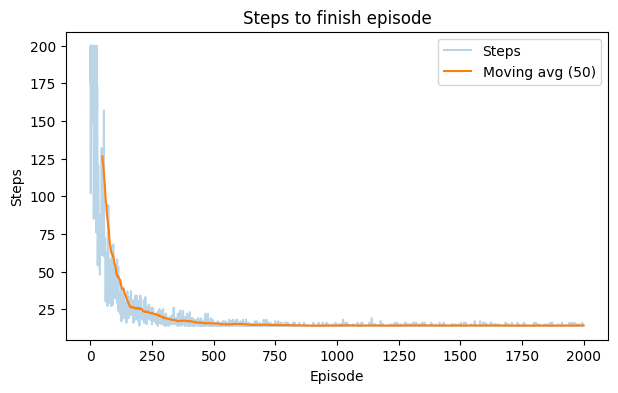

In [9]:
# Figure 3: steps needed to finish each episode
plt.figure(figsize=(7, 4))
plt.plot(steps_per_ep, alpha=0.3, label="Steps")
plt.plot(range(49, len(steps_per_ep)), moving_avg(steps_per_ep), label="Moving avg (50)")
plt.title("Steps to finish episode"); plt.xlabel("Episode"); plt.ylabel("Steps")
plt.legend()
plt.savefig("fig3_steps_curve.png", dpi=150, bbox_inches="tight")
plt.show()

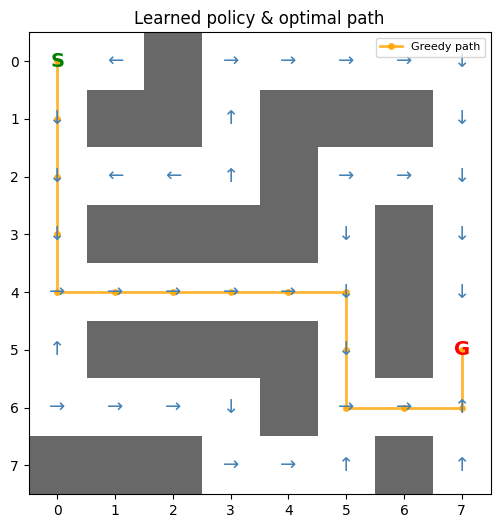

In [10]:
# Figure 4: learned policy (arrow = best action per cell) + greedy path
fig, ax = plt.subplots(figsize=(6, 6))
draw_maze(env, ax)
for r in range(env.n_rows):
    for c in range(env.n_cols):
        if env.grid[r, c] == "#" or (r, c) in (env.start, env.goal):
            continue
        if Q[r, c].max() != 0:                         # skip cells never learned
            ax.text(c, r, ARROWS[int(np.argmax(Q[r, c]))], ha="center", va="center",
                    color="steelblue", fontsize=14)
ys, xs = zip(*path)
ax.plot(xs, ys, "o-", color="orange", linewidth=2, markersize=4, alpha=0.8, label="Greedy path")
ax.set_title("Learned policy & optimal path")
ax.legend(loc="upper right", fontsize=8)
plt.savefig("fig4_policy_path.png", dpi=150, bbox_inches="tight")
plt.show()

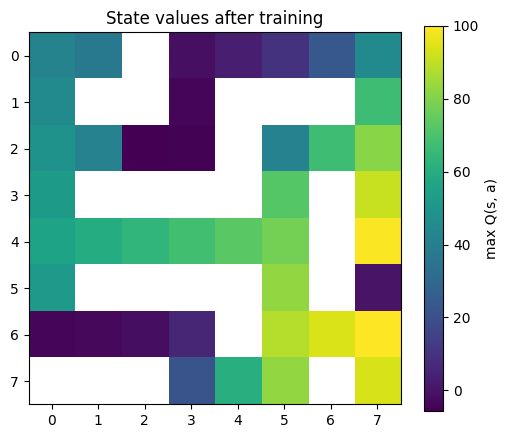

In [11]:
# Figure 5: state-value heatmap, V(s) = max_a Q(s,a)
# Shows how value spreads backward from the goal (brighter = closer to goal)
V = Q.max(axis=2).copy()
V[env.grid == "#"] = np.nan                            # hide walls
plt.figure(figsize=(6, 5))
plt.imshow(V, cmap="viridis")
plt.colorbar(label="max Q(s, a)")
plt.title("State values after training")
plt.savefig("fig5_value_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

In [12]:
# Quick numerical summary to quote in the report
print("Episodes trained      :", EPISODES)
print("Avg reward, first 100 :", round(np.mean(rewards[:100]), 1))
print("Avg reward, last 100  :", round(np.mean(rewards[-100:]), 1))
print("Avg steps, first 100  :", round(np.mean(steps_per_ep[:100]), 1))
print("Avg steps, last 100   :", round(np.mean(steps_per_ep[-100:]), 1))
print("Shortest path found   :", len(path) - 1, "steps")
print("Final epsilon         :", round(max(EPS_END, EPS_START * EPS_DECAY ** EPISODES), 3))

Episodes trained      : 2000
Avg reward, first 100 : -148.5
Avg reward, last 100  : 86.7
Avg steps, first 100  : 90.7
Avg steps, last 100   : 14.1
Shortest path found   : 14 steps
Final epsilon         : 0.01
